In [1]:
import os, json, pickle

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from scipy.signal import find_peaks
from utils.pit.piece_wise_marginal import from_normal

import xarray as xr

from bluemath_tk.core.io import load_model

import cartopy.crs as ccrs
import cartopy.feature as cfeature

#### Load and Prepare Data

In [2]:
point = 'p102'

#### Predictores: 30 PCs de presión + 10 PCs del gradiente reconstruido (6 h)
pcs_msl = pd.read_csv('outputs/pca/pcs_msl_30_6h.csv', index_col=0, parse_dates=True)
pcs_grad = pd.read_csv('outputs/grad_rec/pcs_grad_rec_6h.csv', index_col=0, parse_dates=True)
data_pcs = pcs_msl.join(pcs_grad)

#### Objetivo: Z (PIT + armónica, 00_PIT), media móvil de 6 h centrada, a 00/06/12/18
waves_df_z = pd.read_csv(f'outputs/marginal/z_bulk_{point}.csv', index_col=0, parse_dates=True)
waves_df_z_6h = waves_df_z.rolling('6h', center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin([0, 6, 12, 18])].dropna()

#### Para volver a metros
pit = pickle.load(open(f'outputs/marginal/transformacion_{point}.pkl', 'rb'))

#### Campos reales de ERA5
era5 = xr.open_zarr('data/era5_mslp_grad_1985_2026_1deg_hourly.zarr')
pca_msl = load_model('outputs/pca/pca_msl.pkl')


In [3]:
lags = [0, 6, 12, 18, 24, 30, 36]
X_lagged = pd.concat({f'l{l}': data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(data_pcs.index)
X_lagged.columns = [f'{c}_l{l[1:]}' for l, c in X_lagged.columns]
X_lagged = X_lagged.dropna()

idx = X_lagged.index.intersection(waves_df_z_6h.index)
X = X_lagged.loc[idx]
y = waves_df_z_6h.loc[idx, 'VHM0']
print(X.shape)

(60992, 280)


#### XGBoost (profundidad 3)

In [4]:
xgb_params = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=200,
                  subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=0)

#### CrossValidation (1985–2015, pliegues por años)

In [5]:
tr = idx < '2016-01-01'
X_tr, y_tr = X[tr], y[tr]

f_oof = pd.Series(np.nan, index=X_tr.index)
for i_fit, i_val in GroupKFold(n_splits=5).split(X_tr, y_tr, groups=X_tr.index.year):
    model = XGBRegressor(**xgb_params).fit(X_tr.iloc[i_fit], y_tr.iloc[i_fit])
    f_oof.iloc[i_val] = model.predict(X_tr.iloc[i_val])

#### Full model

In [6]:
xgb_final = XGBRegressor(**xgb_params).fit(X_tr, y_tr)
f_test = pd.Series(xgb_final.predict(X[~tr]), index=X.index[~tr])

#### Métricas

In [7]:
print(f"6-horaria OOF:  {f_oof.corr(y_tr):.3f}")
print(f"6-horaria test: {f_test.corr(y[~tr]):.3f}")
print(f"diaria OOF:     {f_oof.resample('D').mean().corr(y_tr.resample('D').mean()):.3f}")
print(f"diaria test:    {f_test.resample('D').mean().corr(y[~tr].resample('D').mean()):.3f}")

6-horaria OOF:  0.747
6-horaria test: 0.744
diaria OOF:     0.779
diaria test:    0.774


In [8]:
#### Extremos en test, en metros: pico de f (±24 h) / pico observado en temporales > q99
def hs(z):
    zz = waves_df_z.loc[z.index].copy()
    zz['VHM0'] = z.values
    z0 = pit['harm_z'].inverse_transform(zz)['VHM0'].clip(-6.36, 6.36)
    return pd.Series(pit['marg']['VHM0'].ppf(from_normal(z0).values), index=z.index)

hs_obs, hs_f = hs(y[~tr]), hs(f_test)
picos = hs_obs.index[find_peaks(hs_obs.values, height=hs_obs.quantile(0.99), distance=12)[0]]
ratio = pd.Series([hs_f.loc[t - pd.Timedelta('24h'):t + pd.Timedelta('24h')].max() / hs_obs.loc[t] for t in picos], index=picos)
top10 = hs_obs.loc[picos].nlargest(10).index

print(f"temporales test: {len(picos)} | pico f/obs: {ratio.mean():.2f} | 10 mayores: {ratio.loc[top10].mean():.2f}")
print(f"Juliette: obs {hs_obs.loc['2023-02-25':'2023-03-03'].max():.2f} m | f {hs_f.loc['2023-02-25':'2023-03-03'].max():.2f} m")

temporales test: 53 | pico f/obs: 0.73 | 10 mayores: 0.72
Juliette: obs 5.97 m | f 2.86 m


#### Figuras

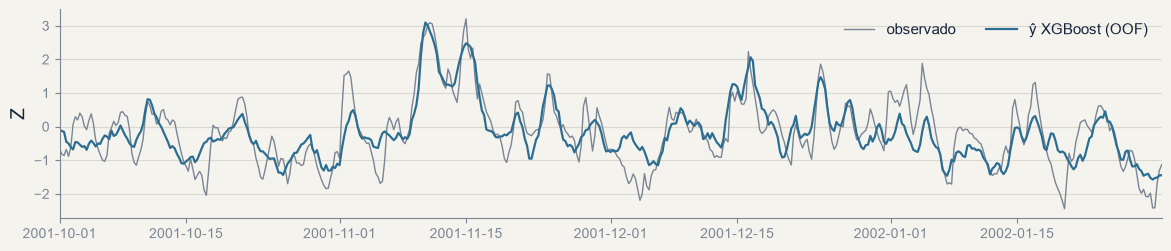

In [9]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

t0, t1 = "2001-10-01", "2002-01-31"

fig, ax = plt.subplots(figsize=(11.6, 2.4), constrained_layout=True, facecolor=FONDO)
ax.plot(y.loc[t0:t1], color=GRIS, lw=1, label="observado")
ax.plot(f_oof.loc[t0:t1], color=AZUL, lw=1.6, label="ŷ XGBoost (OOF)")
ax.axhline(0, color="#DDD8CE", lw=0.8, zorder=0)
ax.set(ylabel="Z", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#DDD8CE", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=11)

fig.savefig("figuras/xgb_serie_invierno.png", dpi=200, facecolor=FONDO)
plt.show()

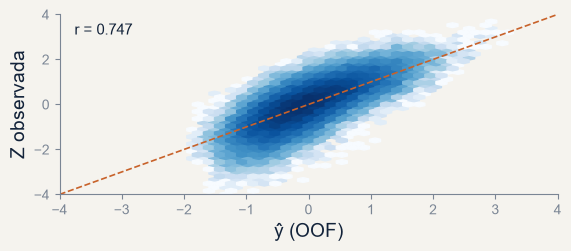

In [10]:
d = pd.concat({"z": y, "f": f_oof}, axis=1).dropna()

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True, facecolor=FONDO)
hb = ax.hexbin(d["f"], d["z"], gridsize=45, cmap="Blues", mincnt=1, bins="log", extent=(-4, 4, -4, 4))
ax.plot([-4, 4], [-4, 4], color=NARANJA, lw=1.2, ls="--")
ax.text(0.03, 0.95, f"r = {d['z'].corr(d['f']):.3f}", transform=ax.transAxes, va="top", fontsize=11)
ax.set(xlabel="ŷ (OOF)", ylabel="Z observada", xlim=(-4, 4), ylim=(-4, 4))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=10)

fig.savefig("figuras/xgb_dispersion.png", dpi=200, facecolor=FONDO)
plt.show()

#### Guardar

In [11]:
out_dir = f'outputs/xgb_{point}'
os.makedirs(out_dir, exist_ok=True)

#### Modelo final + orden de columnas que espera
xgb_final.save_model(f'{out_dir}/xgb_final.json')
with open(f'{out_dir}/xgb_features.json', 'w') as f:
    json.dump({'columns': list(X_tr.columns), 'lags_h': lags, 'params': xgb_params,
               'train': ['1985-01-01', '2015-12-31']}, f, indent=1)

#### Serie horaria: z, f y residuo (OOF en 1985–2015, modelo final en 2016–2025)
f_h = pd.concat([f_oof, f_test]).sort_index().resample('h').interpolate()
z_h = waves_df_z['VHM0'].reindex(f_h.index)

residuos = pd.DataFrame({'z': z_h, 'f': f_h, 'r': z_h - f_h})
residuos['periodo'] = np.where(residuos.index < '2016-01-01', 'oof', 'test')
residuos.dropna(subset=['r']).to_csv(f'{out_dir}/residuos_horarios.csv')
print(residuos.dropna().groupby('periodo')['r'].agg(['count', 'std']))

          count       std
periodo                  
oof      271728  0.673759
test      94219  0.663771


In [12]:
#### Temporales con nombre: Hs observada vs f (OOF hasta 2015, test desde 2016)
f_all = pd.concat([f_oof, f_test]).sort_index()
hs_obs_all, hs_f_all = hs(y), hs(f_all)

picos_all = hs_obs_all.index[find_peaks(hs_obs_all.values, height=hs_obs_all.quantile(0.99), distance=12)[0]]
temporales = {f"{t:%d %b %Y}": (t - pd.Timedelta("1D"), t + pd.Timedelta("1D"))
              for t in hs_obs_all.loc[picos_all].nlargest(6).index}

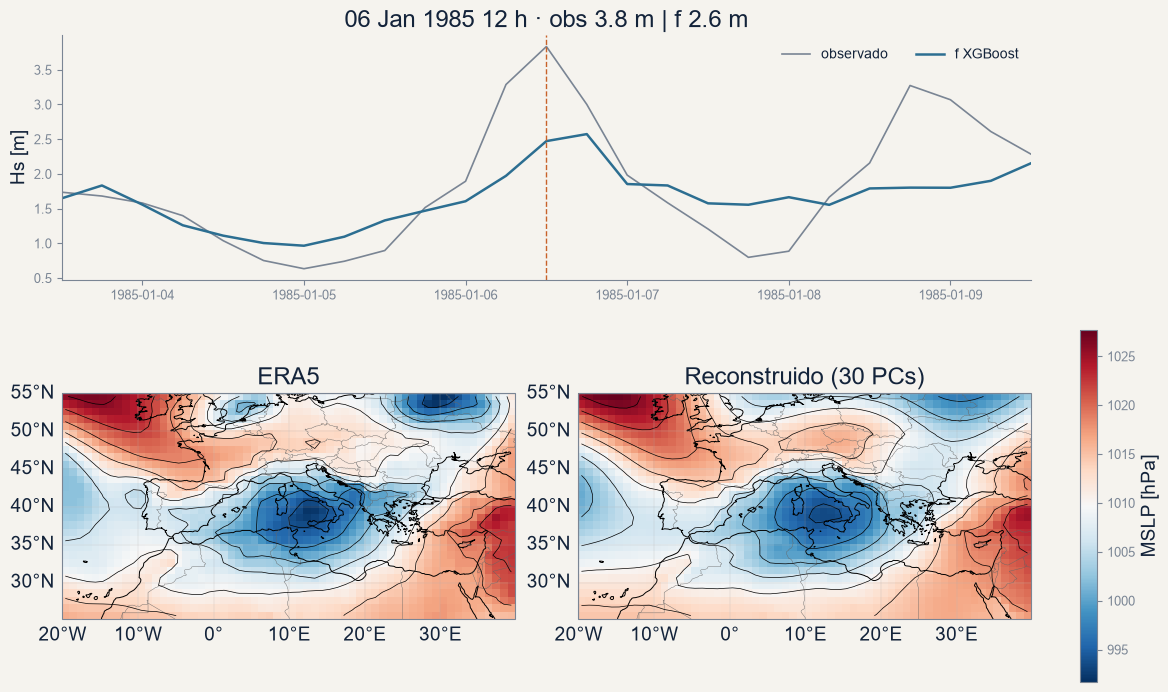

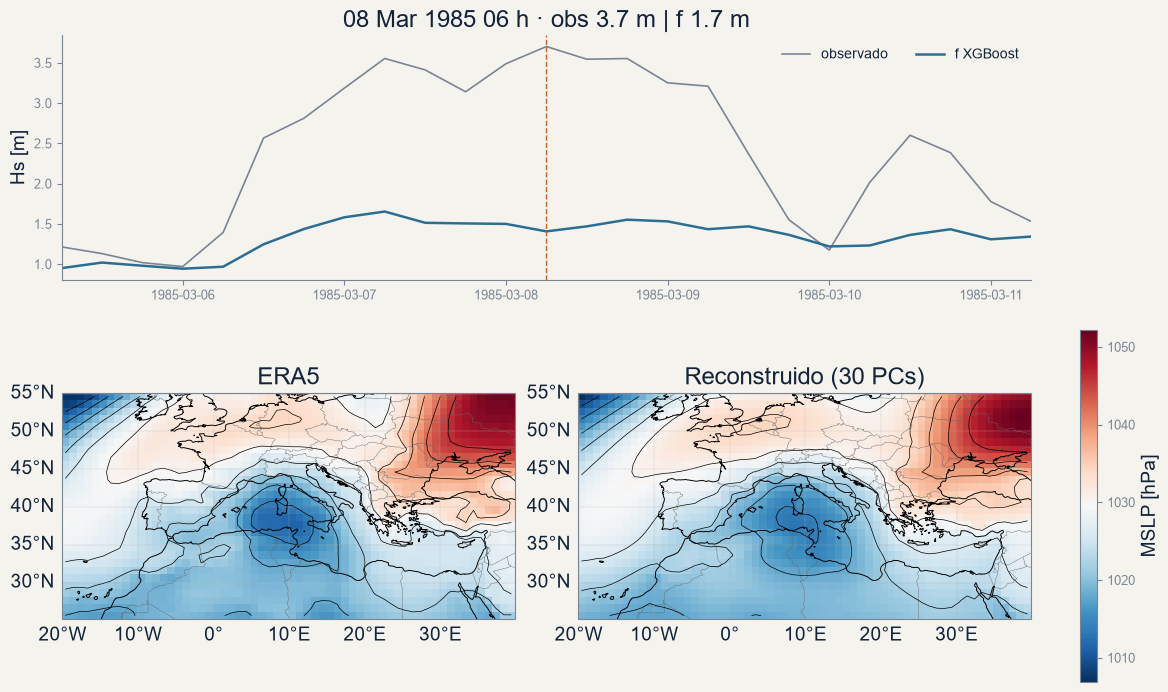

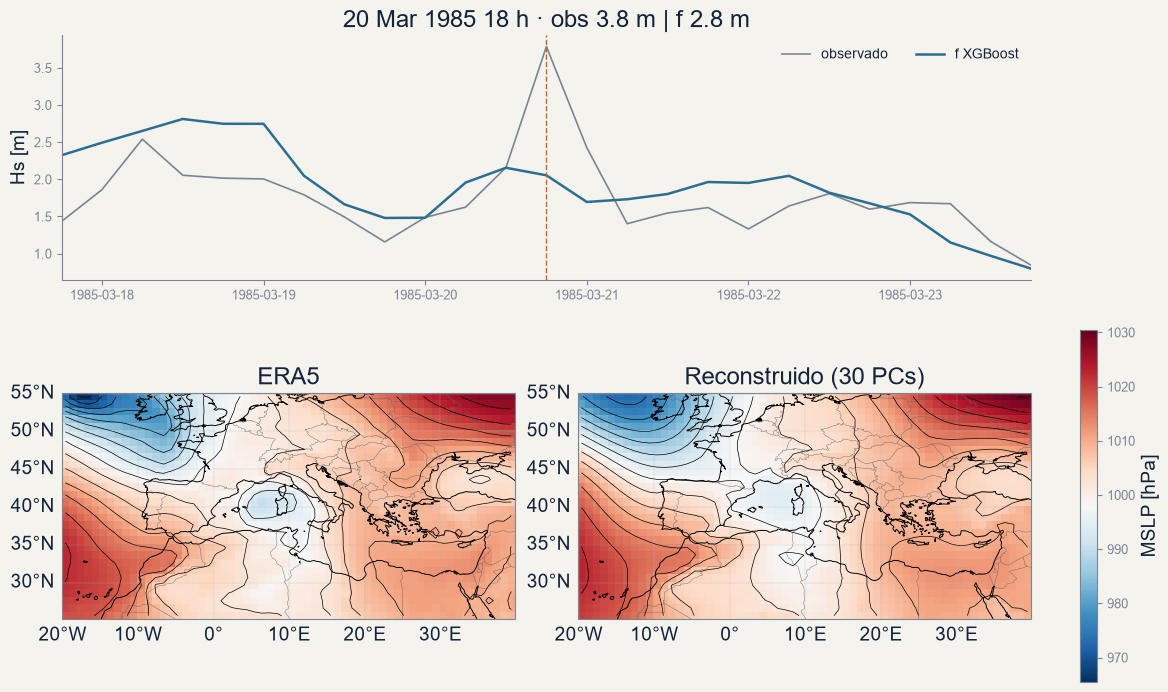

In [13]:
def format_axes(fig):
    for i, ax in enumerate(fig.axes):
        ax.text(0.5, 0.5, "ax%d" % (i+1), va="center", ha="center")
        ax.tick_params(labelbottom=False, labelleft=False)

PROJ = ccrs.PlateCarree()

for storm in picos_all[:3]:
    w0, w1 = storm - pd.Timedelta(days=3), storm + pd.Timedelta(days=3)

    #### Campo real y reconstruido con las 30 PCs en el pico (hPa)
    real = era5['msl'].sel(valid_time=storm) / 100
    pcs_da = xr.DataArray(pcs_msl.loc[[storm]].values, dims=('time', 'n_component'),
                          coords={'time': [storm], 'n_component': np.arange(pcs_msl.shape[1])})
    rec = pca_msl.inverse_transform(pcs_da)['msl'].isel(time=0) / 100
    vmin, vmax = float(min(real.min(), rec.min())), float(max(real.max(), rec.max()))

    fig = plt.figure(figsize=(11.6, 7), layout='constrained', facecolor=FONDO)
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1, 1.6])
    ax1 = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, 0], projection=PROJ)
    ax3 = fig.add_subplot(gs[1, 1], projection=PROJ)

    #### Serie
    ax1.plot(hs_obs_all.loc[w0:w1], color=GRIS, lw=1.2, label='observado')
    ax1.plot(hs_f_all.loc[w0:w1], color=AZUL, lw=1.8, label='f XGBoost')
    ax1.axvline(storm, color=NARANJA, lw=1, ls='--')
    ax1.set(ylabel='Hs [m]', xlim=(w0, w1),
            title=f'{storm:%d %b %Y %H h} · obs {hs_obs_all[storm]:.1f} m | f {hs_f_all.loc[w0:w1].max():.1f} m')
    ax1.legend(frameon=False, loc='upper right', ncol=2, fontsize=10)
    ax1.spines[['top', 'right']].set_visible(False)

    #### Mapas
    for ax, campo, titulo in [(ax2, real, 'ERA5'), (ax3, rec, 'Reconstruido (30 PCs)')]:
        im = campo.plot(ax=ax, transform=PROJ, cmap='RdBu_r', vmin=vmin, vmax=vmax, add_colorbar=False)
        campo.plot.contour(ax=ax, transform=PROJ, levels=np.arange(950, 1050, 4), colors='k', linewidths=0.5)
        ax.coastlines(resolution='50m', lw=0.7)
        ax.add_feature(cfeature.BORDERS, lw=0.3, color='0.4')
        gl = ax.gridlines(draw_labels=True, lw=0.3, color='0.7', alpha=0.6)
        gl.top_labels = gl.right_labels = False
        ax.set_title(titulo)
    fig.colorbar(im, ax=[ax2, ax3], label='MSLP [hPa]', shrink=0.9)

    for ax in fig.axes:
        ax.set_facecolor(FONDO)
        ax.tick_params(labelsize=9)
    plt.show()

#### ¿Sesga el PVAR la f? f con PCs simuladas vs f con PCs históricas

In [14]:
import glob

def f_desde(pcs_m, pcs_g):
    d = pcs_m.join(pcs_g)
    Xs = pd.concat({f'l{l}': d.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(d.index)
    Xs.columns = [f'{c}_l{l[1:]}' for l, c in Xs.columns]
    Xs = Xs.dropna()[X.columns]
    return pd.Series(xgb_final.predict(Xs), index=Xs.index)

#### Histórico 1985–2025 (modelo final, como en el emulador)
f_hist = f_desde(pcs_msl, pcs_grad).loc['1985':'2025']

#### Simulaciones: 41 años completos de cada una (se quita el primer año)
sims_m = sorted(glob.glob('outputs/var_6h/simulaciones_h1/sim_*.parquet'))[:20]
f_sims = []
for fm in sims_m:
    fg = os.path.join('outputs/grad_rec/simulaciones_h1', os.path.basename(fm).replace('sim_', 'grec_'))
    s = f_desde(pd.read_parquet(fm).astype('float64'), pd.read_parquet(fg).astype('float64'))
    a0 = s.index[0].year + 1
    f_sims.append(s.loc[str(a0):str(a0 + 40)])

def resumen(f):
    pk = find_peaks(f.values, height=f_hist.quantile(0.99), distance=12)[0]
    return {'q90': f.quantile(0.90), 'q99': f.quantile(0.99), 'q99.9': f.quantile(0.999),
            'máx anual medio': f.groupby(f.index.year).max().mean(),
            'picos f > q99 hist / década': len(pk) * 10 / f.index.year.nunique()}

h = pd.Series(resumen(f_hist))
s = pd.DataFrame([resumen(f) for f in f_sims])
pd.DataFrame({'histórico': h, 'PVAR mediana': s.median(), 'PVAR p5': s.quantile(0.05), 'PVAR p95': s.quantile(0.95),
              'PVAR / hist': s.median() / h}).round(3)

,histórico,PVAR mediana,PVAR p5,PVAR p95,PVAR / hist
q90,0.931,0.818,0.793,0.833,0.880
q99,1.758,1.629,1.558,1.671,0.926
q99.9,2.444,2.351,2.221,2.473,0.962
máx anual medio,2.354,2.275,2.153,2.391,0.966
picos f > q99 hist / década,42.439,27.561,23.134,30.500,0.649


In [15]:
#### Por estación: picos de f > q99 histórico por década
est = lambda m: np.select([np.isin(m, [12, 1, 2]), np.isin(m, [3, 4, 5]), np.isin(m, [6, 7, 8])], ['invierno', 'primavera', 'verano'], 'otoño')

def picos_est(f):
    pk = f.index[find_peaks(f.values, height=f_hist.quantile(0.99), distance=12)[0]]
    return pd.Series(est(pk.month)).value_counts() * 10 / f.index.year.nunique()

pd.DataFrame({'histórico': picos_est(f_hist),
              'PVAR mediana': pd.concat([picos_est(f) for f in f_sims], axis=1).fillna(0).median(axis=1)}).round(1)

,histórico,PVAR mediana
invierno,16.8,16.3
primavera,10.7,5.6
otoño,8.8,3.4
verano,6.1,2.0
